In [3]:
from azure.core.credentials import AzureKeyCredential
from azure.ai.textanalytics import TextAnalyticsClient
import os
import pandas as pd
import numpy as np
import re
import nltk
from sklearn.metrics import accuracy_score, precision_score, recall_score


In [4]:
os.environ['LANGUAGE_KEY'] = '4pxnoh3RpNdpeDCsZ0vhmf7WACTzItWOhxskeDoRH3xGdGxDPMfwJQQJ99BDAC5RqLJXJ3w3AAAaACOGCwLm'
os.environ['LANGUAGE_ENDPOINT'] = 'https://bibilanguage.cognitiveservices.azure.com/'

endpoint = os.environ['LANGUAGE_ENDPOINT']
key = os.environ['LANGUAGE_KEY']

client = TextAnalyticsClient(endpoint=endpoint, credential=AzureKeyCredential(key))


In [5]:
documents = [
    "By choosing a bike over a car, I’m reducing my environmental footprint. Cycling promotes eco-friendly transportation, and I’m proud to be part of that movement."
]

result = client.analyze_sentiment(documents, show_opinion_mining=True)
docs = [doc for doc in result if not doc.is_error]

print("Let's visualize the sentiment of each of these documents")
for idx, doc in enumerate(docs):
    print(f"Document text: {documents[idx]}")
    print(f"Overall sentiment: {doc.sentiment}")


Let's visualize the sentiment of each of these documents
Document text: By choosing a bike over a car, I’m reducing my environmental footprint. Cycling promotes eco-friendly transportation, and I’m proud to be part of that movement.
Overall sentiment: positive


In [6]:
import csv
import os

In [7]:
# load some data
crtDir =  os.getcwd()
fileName = os.path.join(crtDir, 'data', 'reviews_mixed.csv')

data = []
with open(fileName) as csv_file:
    csv_reader = csv.reader(csv_file, delimiter=',')
    line_count = 0
    for row in csv_reader:
        if line_count == 0:
            dataNames = row
        else:
            data.append(row)
        line_count += 1

inputs = [data[i][0] for i in range(len(data))][:100]
outputs = [data[i][1] for i in range(len(data))][:100]
labelNames = list(set(outputs))

print(inputs[:2])
print(labelNames[:2])


['The rooms are extremely small, practically only a bed.', 'Room safe did not work.']
['positive', 'negative']


In [8]:
# prepare data for training and testing

import numpy as np

np.random.seed(5)
# noSamples = inputs.shape[0]
noSamples = len(inputs)
indexes = [i for i in range(noSamples)]
trainSample = np.random.choice(indexes, int(0.8 * noSamples), replace = False)
testSample = [i for i in indexes  if not i in trainSample]

trainInputs = [inputs[i] for i in trainSample]
trainOutputs = [outputs[i] for i in trainSample]
testInputs = [inputs[i] for i in testSample]
testOutputs = [outputs[i] for i in testSample]

print(trainInputs[:3])


['Just to give you an idea: the shutters of the windows were not working, did not go neither up or down - just hanging down only one side and the other up....', 'and hip and CLEAN!', "Toilet paper wasn't replaced everyday!"]


In [9]:
# extract some features from the raw text

# # representation 1: Bag of Words
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()

trainFeatures = vectorizer.fit_transform(trainInputs)
testFeatures = vectorizer.transform(testInputs)

# vocabulary size
print("vocab size: ", len(vectorizer.vocabulary_),  " words")
# no of emails (Samples)
print("traindata size: ", len(trainInputs), " emails")
# shape of feature matrix
print("trainFeatures shape: ", trainFeatures.shape)

# vocabbulary from the train data
print('some words of the vocab: ', vectorizer.get_feature_names_out()[-20:])
# extracted features
print('some features: ', trainFeatures.toarray()[:3])


vocab size:  341  words
traindata size:  80  emails
trainFeatures shape:  (80, 341)
some words of the vocab:  ['was' 'wasn' 'water' 'we' 'wear' 'well' 'were' 'wet' 'which' 'whole'
 'window' 'windows' 'winter' 'with' 'work' 'working' 'workout' 'would'
 'you' 'your']
some features:  [[0 0 0 ... 0 1 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [10]:
# representation 2: tf-idf features - word granularity
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(max_features=50)

trainFeatures = vectorizer.fit_transform(trainInputs)
testFeatures = vectorizer.transform(testInputs)

# vocabbulary from the train data
print('vocab: ', vectorizer.get_feature_names_out()[:10])
# extracted features
print('features: ', trainFeatures.toarray()[:3])


vocab:  ['all' 'and' 'are' 'at' 'bathroom' 'bed' 'bit' 'clean' 'cold'
 'comfortable']
features:  [[0.         0.14203772 0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.4980966  0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.33735761 0.19218537 0.19992677 0.19992677 0.         0.
  0.         0.         0.         0.         0.         0.
  0.31496244 0.         0.17372323 0.         0.         0.43886705
  0.         0.         0.         0.19218537 0.23237012 0.
  0.21943352 0.19992677]
 [0.         0.81777684 0.         0.         0.         0.
  0.         0.57553543 0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.    

In [11]:
from sklearn.decomposition import TruncatedSVD
svd = TruncatedSVD(n_components=40)
train_lsa = svd.fit_transform(trainFeatures)

# LSA = Latent Semantic Analysis:
# fiecare text un set scurt de 40 valori
# care încearcă să surprindă despre ce e textul
train_lsa

array([[ 0.47610759, -0.17642555,  0.0740722 , ..., -0.14845554,
        -0.14762514,  0.00686955],
       [ 0.24258883, -0.15534386,  0.68844174, ..., -0.11382196,
        -0.0593803 , -0.05700416],
       [ 0.03907344, -0.08692776, -0.02595925, ...,  0.00568136,
         0.00214069,  0.02779947],
       ...,
       [ 0.46309149, -0.28101944,  0.28746274, ...,  0.04285533,
         0.03681195,  0.01937928],
       [ 0.26897209, -0.01800843,  0.40882839, ...,  0.07696508,
        -0.10353481,  0.01036364],
       [ 0.5950421 , -0.25136773,  0.13746945, ..., -0.15115419,
         0.04919189, -0.00872171]], shape=(80, 40))

In [12]:
# alte caracteristici

sentences = [prop[0] for prop in data]
feelings  = [prop[1] for prop in data]


In [13]:
def clasificator_ann_tool(propozitii, sentimente):

    for propozitie, sentiment in zip(propozitii, sentimente):
        document = [propozitie]
        result = client.analyze_sentiment(document, show_opinion_mining=True)
        docs = [doc for doc in result if not doc.is_error]

        for idx, doc in enumerate(docs):
            print(f"Result sentiment: {doc.sentiment}")
        print("Correct sentiment: ", sentiment)
        print("------")

clasificator_ann_tool(sentences, feelings)

Result sentiment: negative
Correct sentiment:  negative
------
Result sentiment: negative
Correct sentiment:  negative
------
Result sentiment: positive
Correct sentiment:  positive
------
Result sentiment: negative
Correct sentiment:  negative
------
Result sentiment: negative
Correct sentiment:  negative
------
Result sentiment: positive
Correct sentiment:  positive
------
Result sentiment: neutral
Correct sentiment:  negative
------
Result sentiment: positive
Correct sentiment:  positive
------
Result sentiment: positive
Correct sentiment:  positive
------
Result sentiment: negative
Correct sentiment:  negative
------
Result sentiment: negative
Correct sentiment:  negative
------
Result sentiment: positive
Correct sentiment:  positive
------
Result sentiment: positive
Correct sentiment:  negative
------
Result sentiment: negative
Correct sentiment:  negative
------
Result sentiment: negative
Correct sentiment:  negative
------
Result sentiment: negative
Correct sentiment:  negative


In [14]:
def print_accuracy(results, truth):
  print('Accuracy: ', accuracy_score(results, truth))
  print('Precision: ', precision_score(results, truth, average='macro', zero_division=0))
  print('Recall: ', recall_score(results, truth, average='macro'))


In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
def plotConfusionMatrix(cm, classNames, title):
    from sklearn.metrics import confusion_matrix
    import itertools

    classes = classNames
    plt.figure()
    plt.imshow(cm, interpolation = 'nearest', cmap = 'Blues')
    plt.title('Confusion Matrix ' + title)
    plt.colorbar()
    tick_marks = np.arange(len(classNames))
    plt.xticks(tick_marks, classNames, rotation=45)
    plt.yticks(tick_marks, classNames)

    text_format = 'd'
    thresh = cm.max() / 2.
    for row, column in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(column, row, format(cm[row, column], text_format),
                horizontalalignment = 'center',
                color = 'white' if cm[row, column] > thresh else 'black')

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()

    plt.show()


In [16]:
from sklearn import neural_network
from sklearn.metrics import confusion_matrix
def ANN_prediction_tool(TrainInputs, TrainOutputs, TestInputs, TestOutputs, text):
  vectorizer = CountVectorizer()

  train_features = vectorizer.fit_transform(TrainInputs)
  test_features = vectorizer.transform(TestInputs)

  classifier = neural_network.MLPClassifier(hidden_layer_sizes=(16, 8),
                                            activation='relu',
                                            max_iter=1000,
                                            solver='sgd',
                                            verbose=True,
                                            random_state=5,
                                            learning_rate_init=0.01,
                                            learning_rate='adaptive')
  classifier.fit(train_features, TrainOutputs)
  predictions = classifier.predict(test_features)

  print_accuracy(predictions, TestOutputs)
  cm = confusion_matrix(TestOutputs, predictions)
  plotConfusionMatrix(cm, ['negative','positive'], '')

  text_features = vectorizer.transform(text)
  prediction = classifier.predict(text_features)
  print('------------------------------------------------------------------------------------------')
  print(text)
  print(prediction)


Iteration 1, loss = 0.82013271
Iteration 2, loss = 0.81560604
Iteration 3, loss = 0.80928546
Iteration 4, loss = 0.80146448
Iteration 5, loss = 0.79243446
Iteration 6, loss = 0.78248367
Iteration 7, loss = 0.77189561
Iteration 8, loss = 0.76086729
Iteration 9, loss = 0.74958272
Iteration 10, loss = 0.73814872
Iteration 11, loss = 0.72674074
Iteration 12, loss = 0.71545843
Iteration 13, loss = 0.70438367
Iteration 14, loss = 0.69359664
Iteration 15, loss = 0.68315861
Iteration 16, loss = 0.67311219
Iteration 17, loss = 0.66348638
Iteration 18, loss = 0.65433376
Iteration 19, loss = 0.64567136
Iteration 20, loss = 0.63747337
Iteration 21, loss = 0.62975222
Iteration 22, loss = 0.62248058
Iteration 23, loss = 0.61564113
Iteration 24, loss = 0.60923302
Iteration 25, loss = 0.60325237
Iteration 26, loss = 0.59766991
Iteration 27, loss = 0.59247151
Iteration 28, loss = 0.58763772
Iteration 29, loss = 0.58314323
Iteration 30, loss = 0.57897672
Iteration 31, loss = 0.57511540
Iteration 32, los

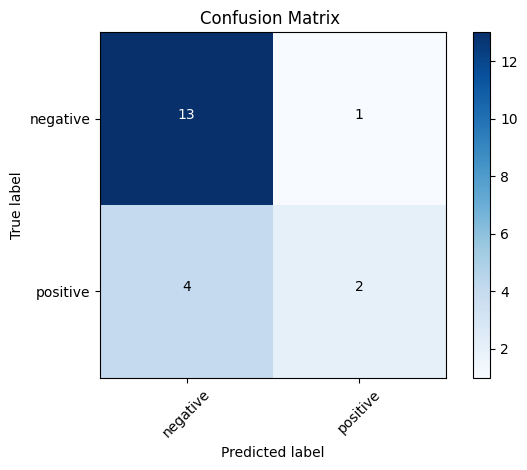

------------------------------------------------------------------------------------------
['By choosing a bike over a car, I’m reducing my environmental footprint. Cycling promotes eco-friendly transportation, and I’m proud to be part of that movement.']
['negative']


In [17]:
text = ['By choosing a bike over a car, I’m reducing my environmental footprint. Cycling promotes eco-friendly transportation, and I’m proud to be part of that movement.']
ANN_prediction_tool(trainInputs, trainOutputs, testInputs, testOutputs, text)


Epoch 0 | Loss: 0.2260
Epoch 10 | Loss: 0.1797
Epoch 20 | Loss: 0.1789
Epoch 30 | Loss: 0.1781
Epoch 40 | Loss: 0.1773
Epoch 50 | Loss: 0.1765
Epoch 60 | Loss: 0.1756
Epoch 70 | Loss: 0.1747
Epoch 80 | Loss: 0.1737
Epoch 90 | Loss: 0.1727
Epoch 100 | Loss: 0.1716
Epoch 110 | Loss: 0.1704
Epoch 120 | Loss: 0.1691
Epoch 130 | Loss: 0.1678
Epoch 140 | Loss: 0.1663
Epoch 150 | Loss: 0.1647
Epoch 160 | Loss: 0.1630
Epoch 170 | Loss: 0.1612
Epoch 180 | Loss: 0.1592
Epoch 190 | Loss: 0.1570
Epoch 200 | Loss: 0.1547
Epoch 210 | Loss: 0.1522
Epoch 220 | Loss: 0.1495
Epoch 230 | Loss: 0.1467
Epoch 240 | Loss: 0.1436
Epoch 250 | Loss: 0.1403
Epoch 260 | Loss: 0.1369
Epoch 270 | Loss: 0.1332
Epoch 280 | Loss: 0.1294
Epoch 290 | Loss: 0.1254
Epoch 300 | Loss: 0.1213
Epoch 310 | Loss: 0.1170
Epoch 320 | Loss: 0.1127
Epoch 330 | Loss: 0.1082
Epoch 340 | Loss: 0.1038
Epoch 350 | Loss: 0.0993
Epoch 360 | Loss: 0.0948
Epoch 370 | Loss: 0.0904
Epoch 380 | Loss: 0.0861
Epoch 390 | Loss: 0.0819
Epoch 400 |

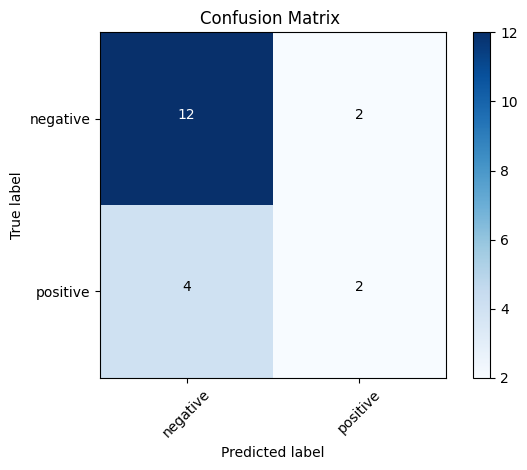

Text: By choosing a bike over a car, I’m reducing my environmental footprint. Cycling promotes eco-friendly transportation, and I’m proud to be part of that movement.
Predicted Sentiment: negative


In [21]:
from ANN import ANN
from sklearn.preprocessing import LabelEncoder

def ANN_implementat(TrainInputs, TrainOutputs, TestInputs, TestOutputs, text):
    vectorizer = CountVectorizer()

    # Vectorization
    X_train = vectorizer.fit_transform(TrainInputs).toarray()
    X_test = vectorizer.transform(TestInputs).toarray()

    # Encode labels
    le = LabelEncoder()
    y_train = le.fit_transform(trainOutputs).reshape(-1, 1)
    y_test = le.transform(testOutputs).reshape(-1, 1)

    # Initialize and train ANN
    ann = ANN(input_size=X_train.shape[1], hidden_size=32, output_size=1)
    ann.train(X_train, y_train, epochs=1000)

    # Predict
    y_pred = ann.predict(X_test)

    # Accuracy
    accuracy = np.mean(y_pred == y_test)
    print(f"\nTest Accuracy: {accuracy:.2f}")

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plotConfusionMatrix(cm, ['negative','positive'], '')

    # Predict custom text
    text_features = vectorizer.transform(text).toarray()
    text_prediction = ann.predict(text_features)
    predicted_labels = le.inverse_transform(text_prediction.flatten())

    for i, t in enumerate(text):
        print(f"Text: {t}")
        print(f"Predicted Sentiment: {predicted_labels[i]}")


ANN_implementat(trainInputs, trainOutputs, testInputs, testOutputs, text)
